In [1]:
import numpy as np
import numpy.linalg as la
import pickle as pkl
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import collections as mc
from scipy.spatial.distance import cdist
from scipy.optimize import linprog
from scipy.linalg import block_diag
from dataclasses import dataclass
from copy import copy, deepcopy
import math
import networkx as nx
import seaborn as sns
import pandas as pd
import cobra
import os
from kneed import KneeLocator
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

plt.rcParams['figure.figsize'] = [7,7]


In [2]:
D_g = 600.          # Coefficient of diffusion of glucose (μm²/s)
cinf_g = 5000.      # Background concentration of glucose (μM)
D_l = 1089           # Coefficient of diffusion of acetate (μm²/s)
cinf_l = 0.         # Background concentration of acetate (μM)
D_o = 2000.         # Coefficient of diffusion of oxygen  (μm²/s)
bf = 4              # Factor for correcting replenishment from boundary
cinf_o = 250. * bf  # Background concentration of oxygen  (μM)
D_h = 7000.         # Coefficient of diffusion of H+ ions (μm²/s)
cinf_h = 1.e-1      # Background concentration of H+ ions (μM)
radius = 1.         # Radius of cells
cell_mass = 5000.e-15   # Mass of each cell
mmolgh_per_uMpersec = 3600 * 1.e-3 * (1.e-5)**3 / cell_mass

f_g_max = cinf_g * D_g * radius
f_o_max = cinf_o * D_o * radius
f_l_min = cinf_l * D_l * radius

import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap



import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.proj3d import proj_transform
from mpl_toolkits.mplot3d.axes3d import Axes3D

import numpy as np
from matplotlib.patches import FancyArrowPatch


class Arrow3D(FancyArrowPatch):

    def __init__(self, x, y, z, dx, dy, dz, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._xyz = (x, y, z)
        self._dxdydz = (dx, dy, dz)

    def draw(self, renderer):
        x1, y1, z1 = self._xyz
        dx, dy, dz = self._dxdydz
        x2, y2, z2 = (x1 + dx, y1 + dy, z1 + dz)

        xs, ys, zs = proj_transform((x1, x2), (y1, y2), (z1, z2), self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        super().draw(renderer)
        
    def do_3d_projection(self, renderer=None):
        x1, y1, z1 = self._xyz
        dx, dy, dz = self._dxdydz
        x2, y2, z2 = (x1 + dx, y1 + dy, z1 + dz)

        xs, ys, zs = proj_transform((x1, x2), (y1, y2), (z1, z2), self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))

        return np.min(zs) 

def _arrow3D(ax, x, y, z, dx, dy, dz, *args, **kwargs):
    '''Add an 3d arrow to an `Axes3D` instance.'''

    arrow = Arrow3D(x, y, z, dx, dy, dz, *args, **kwargs)
    ax.add_artist(arrow)


setattr(Axes3D, 'arrow3D', _arrow3D)


def periodic_distance_to_point(point, cell, window_size):
    dx = min(window_size-np.abs(point[0]-cell[0]), np.abs(point[0]-cell[0]))
    if dx == np.abs(point[0]-cell[0]):
        dx = point[0]-cell[0]
    dy = min(window_size-np.abs(point[1]-cell[1]), np.abs(point[1]-cell[1]))
    if dy== np.abs(point[1]-cell[1]):
        dy = point[1]-cell[1]
    dz = min(window_size-np.abs(point[2]-cell[2]), np.abs(point[2]-cell[2]))
    if dz==np.abs(point[2]-cell[2]):
        dz = point[2]-cell[2]
    return math.sqrt((dx)**2+(dy)**2+(dz)**2), dx, dy, dz

def non_periodic_distance_to_point(point, cell, window_size):
    d_ij = math.sqrt((point[0]-cell[0])**2+(point[1]-cell[1])**2+(point[2]-cell[2])**2)
    dx = point[0]-cell[0]
    #if dx>0: 
    #    dx = dx - 0.3
    #else: 
    #    dx = dx + 0.3
    dy = point[1]-cell[1]
    #if dy >0: 
    #    dy = dy - 0.3
    #else:
    #    dy = dy + 0.3
    dz = point[2]-cell[2]
    #if dz >0: 
    #    dz = dz - 0.3
    #else:
    #    dz = dz + 0.3
    return d_ij, dx, dy, dz


def calculate_field(cells_pos, fluxes, compound, window_size=2000):
    step = window_size/30
    if compound == 'glu':
        cinf = cinf_g
        D = D_g    
    if compound == 'ox':
        cinf = cinf_o
        D = D_o
    if compound=='ac':
        cinf = cinf_l
        D = D_l
        fluxes = fluxes
       # fluxes = fluxes*-1
    Y_vals = []
    X_vals = []
    Z_vals = []
    y = window_size
    field = []
    while y>0:
        x = 0
        while x<window_size: 
            z = 0
            row = []
            while z<window_size:
                #print(x,y,z)
                C = cinf
                for n,cell in enumerate(cells_pos):
                    dist, dx, dy, dz = periodic_distance_to_point([x,y,z], cell, window_size)
                    if dist > radius/2:
                        #print(fluxes[n])
                        C -= fluxes[n]/(D*dist)       
                    else:
                        C = 0
                        break
                    #print(C)
                if C<0: 
                    C = 0
                row.append(C)
                Y_vals.append(y)
                X_vals.append(x)
                Z_vals.append(z)
                z += step
            x += step
        field.append(row)
        y -= step

    return X_vals, Y_vals, Z_vals, field

def calculate_distances(cells_pos, window_size=50, dim=2):
    num_cells = len(cells_pos)
    distances = np.identity(num_cells)
    for i,cell1 in enumerate(cells_pos):
        for j,cell2 in enumerate(cells_pos):
            if i==j:
                distances[i][j] = window_size*10000
            else:
                if dim == 3: 
                    dx = abs(cell2[0] - cell1[0])
                    if dx > window_size/2:
                        dx = window_size - dx
                    dy = abs(cell2[1] - cell1[1])
                    if dy > window_size/2:
                        dy = window_size - dy
                    dz = abs(cell2[2] - cell1[2])
                    if dz > window_size/2:
                        dz = window_size - dz
                    distances[i][j] = math.sqrt(dx ** 2 + dy ** 2 + dz ** 2)
                else: 
                    distances[i][j] = math.sqrt((cell2[0] - cell1[0]) ** 2 + (cell2[1] - cell1[1]) ** 2 +
                                                (cell2[2] - cell1[2]) ** 2)
    return distances


def infer_network(cells_pos, fluxes, vmin, vmax, window_size):
    
   # arrows = []
   # min_dist = 400
   # min_flux = 0.1
   #
   # for i,cell1 in enumerate(cells_pos):
   #     for j,cell2 in enumerate(cells_pos): 
   #         if i != j and abs(fluxes[i])>min_flux:
   #             if fluxes[i]/fluxes[j] < 0 and abs(fluxes[j])>min_flux:
   #                 d_ij, dx, dy, dz = periodic_distance_to_point(cell1, cell2, window_size=2000)
   #                 #print(d_ij)
   #                 if d_ij < min_dist:
   #                     if fluxes[i] > fluxes[j]:
   #                         #print(cell1, fluxes[i], cell2, fluxes[j])
   #                         arrows.append([cell1[0],cell1[1],cell1[2], -dx, -dy, -dz])
   #                     else:
   #                         arrows.append([cell2[0],cell2[1],cell2[2], dx, dy, dz])
   #  
    
    arrows = []

    #treshold = abs(np.mean([f for f in fluxes if f<0]))/20
    #treshold = (np.mean([abs(f) for f in fluxes if f<0]))**2/2
    #treshold = abs((np.mean([f for f in fluxes])))

    treshold = np.std([f for f in fluxes])/len(fluxes)**(1/2)
    print(treshold)
    distances = calculate_distances(cell_pos, window_size=window_size, dim = 3)
    
    #total_dist = 0
    #total_pairs = 0
    #for i in range(0,len(distances)):
    #    for j in range(0,len(distances)):
    #        if i!=j: 
    #            total_dist+=distances[i][j]
    #            total_pairs+=1
    #treshold = treshold/(total_dist/total_pairs)
    #print(treshold)
    
    G = nx.DiGraph()  # or DiGraph, MultiGraph, MultiDiGraph, etc
    cmap = mpl.cm.get_cmap('viridis')
    norm =  mpl.colors.Normalize(vmin, vmax)
    norm2 = mpl.colors.Normalize(0, max(abs(vmin), vmax))
    
    node_colors = {}
    node_sizes = {}
    for i,cell1 in enumerate(cells_pos):
        if fluxes[i]<0: 
            for j,cell2 in enumerate(cells_pos): 
                if i != j and fluxes[i]/fluxes[j] < 0:
                    d_ij, dx, dy, dz = non_periodic_distance_to_point(cell1, cell2, window_size=window_size)
                    exchange = -fluxes[i]*fluxes[j]/d_ij
                    #exchange = (abs(fluxes[i])+abs(fluxes[j]))/d_ij
                    absorbers = 0
                    for n,f in enumerate(fluxes):
                        if f>0:   
                            absorbers += f/distances[i][n]
                    exchange = exchange/absorbers
                    #print(exchange)
                    if exchange>treshold:
                        arrows.append([cell1[0],cell1[1],cell1[2], -dx, -dy, -dz])
                        G.add_edge(i,j, weight=exchange, length=d_ij-20)
                        if i not in node_colors.keys():
                            #node_colors[i] = cmap(norm(fluxes[i]))
                            if fluxes[i]<0:
                                node_colors[i] = 'mediumspringgreen'
                            else: 
                                node_colors[i] = 'red'
                            node_sizes[i] = norm2(abs(fluxes[i]))
                        if j not in node_colors.keys():
                            #node_colors[j] = cmap(norm(fluxes[j]))
                            if fluxes[j]<0:
                                node_colors[j] = 'mediumspringgreen'
                            else: 
                                node_colors[j] = 'red'
                            node_sizes[j] = norm2(abs(fluxes[j]))
                       
    return arrows, G, node_colors, node_sizes


def plot(cells_pos, X, Y, Z, C, fluxes, compound = '', window_size=50):
    
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    
    vmin=min(fluxes) 
    vmax= max(fluxes)
    
    xs = [i[0] for i in cells_pos]
    ys = [i[1] for i in cells_pos]
    zs = [i[2] for i in cells_pos]
    
    # Create a truncated version of the viridis colormap (removing dark blue tones)
    def truncate_colormap(cmap, min_val=0.2, max_val=1.0, n=100):
        return LinearSegmentedColormap.from_list(
            'truncated_cmap', cmap(np.linspace(min_val, max_val, n))
        )
    
    cmap = truncate_colormap(cm.coolwarm, min_val=0.2, max_val=1)
    cmap = LinearSegmentedColormap.from_list("custom", [ "blue", "#fedccb",'#ffc643', "red", '#cb0000'], N=100)

    p = ax.scatter(xs, ys, zs, s=120, c=fluxes, linewidth=0.5, edgecolors='black', alpha=1,
                cmap = cmap,vmin=vmin, vmax=vmax)
    cbar2= fig.colorbar(p, ticks=np.arange(round(min(fluxes),2),round(max(fluxes),2),0.05), 
                        fraction=0.04, pad=0.04,orientation='vertical', shrink=0.8)
    cbar2.set_label('Acid flux (mmol / gDW·h)',  size=18) #labelpad =10,
    cbar2.ax.tick_params(labelsize=16, rotation=45) 

    #cbar2 = ax.colorbar()
    #ax.set_xlim3d(0,window_size-50)
    #ax.set_ylim3d(0,window_size-50)
    #ax.set_zlim3d(0,window_size-50)
    ax.set_xlim3d(0,window_size)
    ax.set_ylim3d(0,window_size)
    ax.set_zlim3d(0,window_size)
    

    ax.plot([0, window_size-1], [window_size-2, window_size-2], [0, 0], color='black', linewidth=1.5)  # X-axis
    ax.plot([0, 0], [0, window_size-1], [0, 0], color='black', linewidth=1.5)  # Y-axis
    ax.plot([0, 0], [window_size-2, window_size-2], [0, window_size-1], color='black', linewidth=1.5)  # Z-axis

    #ax.plot([0, window_size-20], [window_size-50, window_size-50], [0, 0], color='black', linewidth=1.5)  # X-axis
    #ax.plot([0, 0], [0, window_size-20], [0, 0], color='black', linewidth=1.5)  # Y-axis
    #ax.plot([0, 0], [window_size-50, window_size-50], [0, window_size-20], color='black', linewidth=1.5)  # Z-axis

    #cbar2.set_label('Flux (mmol ac/ gdw·h)', rotation=270, labelpad = 10)
    
    ax.set_xlabel('X coordinate ($\mu$m)', fontsize=15)
    ax.set_ylabel('Y coordinate ($\mu$m)', fontsize=15)
    ax.set_zlabel('Z coordinate ($\mu$m)', fontsize=15)
    ax.w_xaxis.set_pane_color((0.8, 0.8, 0.8, 0.5))  # Light gray, 50% transparent
    ax.w_yaxis.set_pane_color((0.8, 0.8, 0.8, 0.5))
    ax.w_zaxis.set_pane_color((0.8, 0.8, 0.8, 0.5))
    ax.grid(False)
    
    arrows, G, node_colors, node_sizes = infer_network(cells_pos, fluxes,vmin, vmax, window_size)
    #print(arrows)
    for arrow in arrows:
        ax.arrow3D(arrow[0],arrow[1],arrow[2], arrow[3],arrow[4], arrow[5], 
                              mutation_scale=10, arrowstyle="-|>", alpha = 0.7, color='black')
    plt.show()
    
    return G, node_colors, node_sizes
    

def plot_fluxes(cells_pos, fluxes, compound, window_size=50):
    #%matplotlib widget
    X, Y, Z, C = calculate_field(cells_pos, fluxes, compound, window_size)
    G, node_colors,node_sizes = plot(cells_pos, X, Y, Z, C, fluxes,compound, window_size)
    return G, node_colors, node_sizes, C

    

In [12]:
import numpy as np
import math
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import LinearSegmentedColormap, Normalize
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import FancyArrowPatch


import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap



import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.proj3d import proj_transform
from mpl_toolkits.mplot3d.axes3d import Axes3D

import numpy as np
from matplotlib.patches import FancyArrowPatch


# =========================
# PARAMETERS (compact)
# =========================
params = {
    "glu": {"D": 600.0,  "cinf": 5000.0},
    "lac": {"D": 1089.0, "cinf": 0.0},
    "ox":  {"D": 2000.0, "cinf": 250.0 * 4},
    "h":   {"D": 7000.0, "cinf": 1e-1},
}

radius = 1.0
cell_mass = 5000e-15

mmolgh_per_uMpersec = 3600 * 1e-3 * (1e-5)**3 / cell_mass

# Precomputed max fluxes
f_max = {k: v["cinf"] * v["D"] * radius for k, v in params.items()}


class Arrow3D(FancyArrowPatch):

    def __init__(self, x, y, z, dx, dy, dz, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._xyz = (x, y, z)
        self._dxdydz = (dx, dy, dz)

    def draw(self, renderer):
        x1, y1, z1 = self._xyz
        dx, dy, dz = self._dxdydz
        x2, y2, z2 = (x1 + dx, y1 + dy, z1 + dz)

        xs, ys, zs = proj_transform((x1, x2), (y1, y2), (z1, z2), self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        super().draw(renderer)
        
    def do_3d_projection(self, renderer=None):
        x1, y1, z1 = self._xyz
        dx, dy, dz = self._dxdydz
        x2, y2, z2 = (x1 + dx, y1 + dy, z1 + dz)

        xs, ys, zs = proj_transform((x1, x2), (y1, y2), (z1, z2), self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))

        return np.min(zs) 

def _arrow3D(ax, x, y, z, dx, dy, dz, *args, **kwargs):
    '''Add an 3d arrow to an `Axes3D` instance.'''

    arrow = Arrow3D(x, y, z, dx, dy, dz, *args, **kwargs)
    ax.add_artist(arrow)
setattr(Axes3D, 'arrow3D', _arrow3D)


# =========================
# DISTANCES (vectorized style helpers)
# =========================
def periodic_delta(d, L):
    return np.where(d > L/2, d - L, np.where(d < -L/2, d + L, d))


def periodic_distance(p, c, L):
    d = np.array(p) - np.array(c)
    d = periodic_delta(d, L)
    return np.linalg.norm(d), d


def euclidean_distance(p, c):
    d = np.array(p) - np.array(c)
    return np.linalg.norm(d), d


# =========================
# FIELD CALCULATION (simplified lookup)
# =========================
def calculate_field(cells_pos, fluxes, compound, window_size=2000, step_div=30):
    D = params[compound]["D"]
    cinf = params[compound]["cinf"]

    step = window_size / step_div
    grid_vals = []

    for y in np.arange(window_size, 0, -step):
        for x in np.arange(0, window_size, step):
            for z in np.arange(0, window_size, step):

                C = cinf
                for f, cell in zip(fluxes, cells_pos):
                    dist, _ = periodic_distance((x, y, z), cell, window_size)

                    if dist < radius / 2:
                        C = 0
                        break

                    C -= f / (D * dist)

                grid_vals.append(max(C, 0))

    return np.array(grid_vals)


# =========================
# NETWORK INFERENCE (faster structure)
# =========================
def infer_network(cells_pos, fluxes, window_size, vmin, vmax):
    cells_pos = np.array(cells_pos)
    fluxes = np.array(fluxes)

    n = len(fluxes)
    arrows = []

    thresh = np.std(fluxes) / np.sqrt(n) * 0.8
    G = {}

    positive = np.where(fluxes > 0)[0]
    negative = np.where(fluxes < 0)[0]
    
    for i in positive:
        for j in negative:
    
            _, dvec = euclidean_distance(cells_pos[i], cells_pos[j])
            dist = np.linalg.norm(dvec)
    
            exchange = (-fluxes[i] * fluxes[j]) / (dist + 1e-9)
    
            if exchange > thresh:
                arrows.append([*cells_pos[i], *(-dvec)])
                G.setdefault(i, []).append((j, exchange))

    node_colors = {
        i: ("mediumspringgreen" if f < 0 else "red")
        for i, f in enumerate(fluxes)
    }

    node_sizes = {i: abs(f) for i, f in enumerate(fluxes)}

    return arrows, G, node_colors, node_sizes

from matplotlib.colors import TwoSlopeNorm
# =========================
# PLOTTING (cleaned)
# =========================
def plot(cells_pos, fluxes, window_size=50):
    fig = plt.figure(dpi=200)
    ax = fig.add_subplot(projection="3d")

    cells_pos = np.array(cells_pos)
    fluxes = np.array(fluxes)
    
    values = np.array(fluxes)
    
    vmin = np.min(values)
    vmax = np.max(values)
    
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
    
    sc = ax.scatter(
        cells_pos[:, 0],
        cells_pos[:, 1],
        cells_pos[:, 2],
        s=120,
        c=values,
        cmap="RdBu_r",
        norm=norm,
        edgecolors="black",
        linewidths=0.5,
        alpha=0.9
    )

    #sc = ax.scatter(
    #    cells_pos[:, 0],
    #    cells_pos[:, 1],
    #    cells_pos[:, 2],
    #    c=fluxes,
    #    cmap=cmap,
    #    edgecolors="black",
    #    s=120,
    #)

    cbar= plt.colorbar(sc, ax=ax, fraction = 0.03, pad=0.02)
    cbar.set_label('Acid flux (mmol / gDW·h)',  size=12) #labelpad =10,

    neg_ticks = np.linspace(vmin, 0, 4)   # negative arm
    pos_ticks = np.linspace(0, vmax, 4)    # positive arm
    
    ticks = np.unique(np.concatenate([neg_ticks, pos_ticks]))
    
    cbar.set_ticks(ticks)
    cbar.set_ticklabels([f"{t:.2g}" for t in ticks])

    ax.set_xlim(0, window_size)
    ax.set_ylim(0, window_size)
    ax.set_zlim(0, window_size)

    arrows, G, node_colors, node_sizes = infer_network(
        cells_pos, fluxes, window_size,
        fluxes.min(), fluxes.max()
    )

    for x, y, z, dx, dy, dz in arrows:
        ax.arrow3D(x, y, z, dx, dy, dz,  
                              mutation_scale=10, arrowstyle="-|>", alpha = 0.4, color='black')
        #ax.add_artist(arrow)
        #ax.quiver(x, y, z, dx, dy, dz,  alpha = 0.7, color='black')
    ax.set_xlabel('X coordinate ($\mu$m)', fontsize=15)
    ax.set_ylabel('Y coordinate ($\mu$m)', fontsize=15)
    ax.set_zlabel('Z coordinate ($\mu$m)', fontsize=15)
    plt.savefig('interaction_network.png', format='png', dpi=200, bbox_inches='tight')
    plt.show()

    return G, node_colors, node_sizes


# =========================
# WRAPPER
# =========================
def plot_fluxes(cells_pos, fluxes, compound, window_size=50):
    return plot(cells_pos, fluxes, window_size)

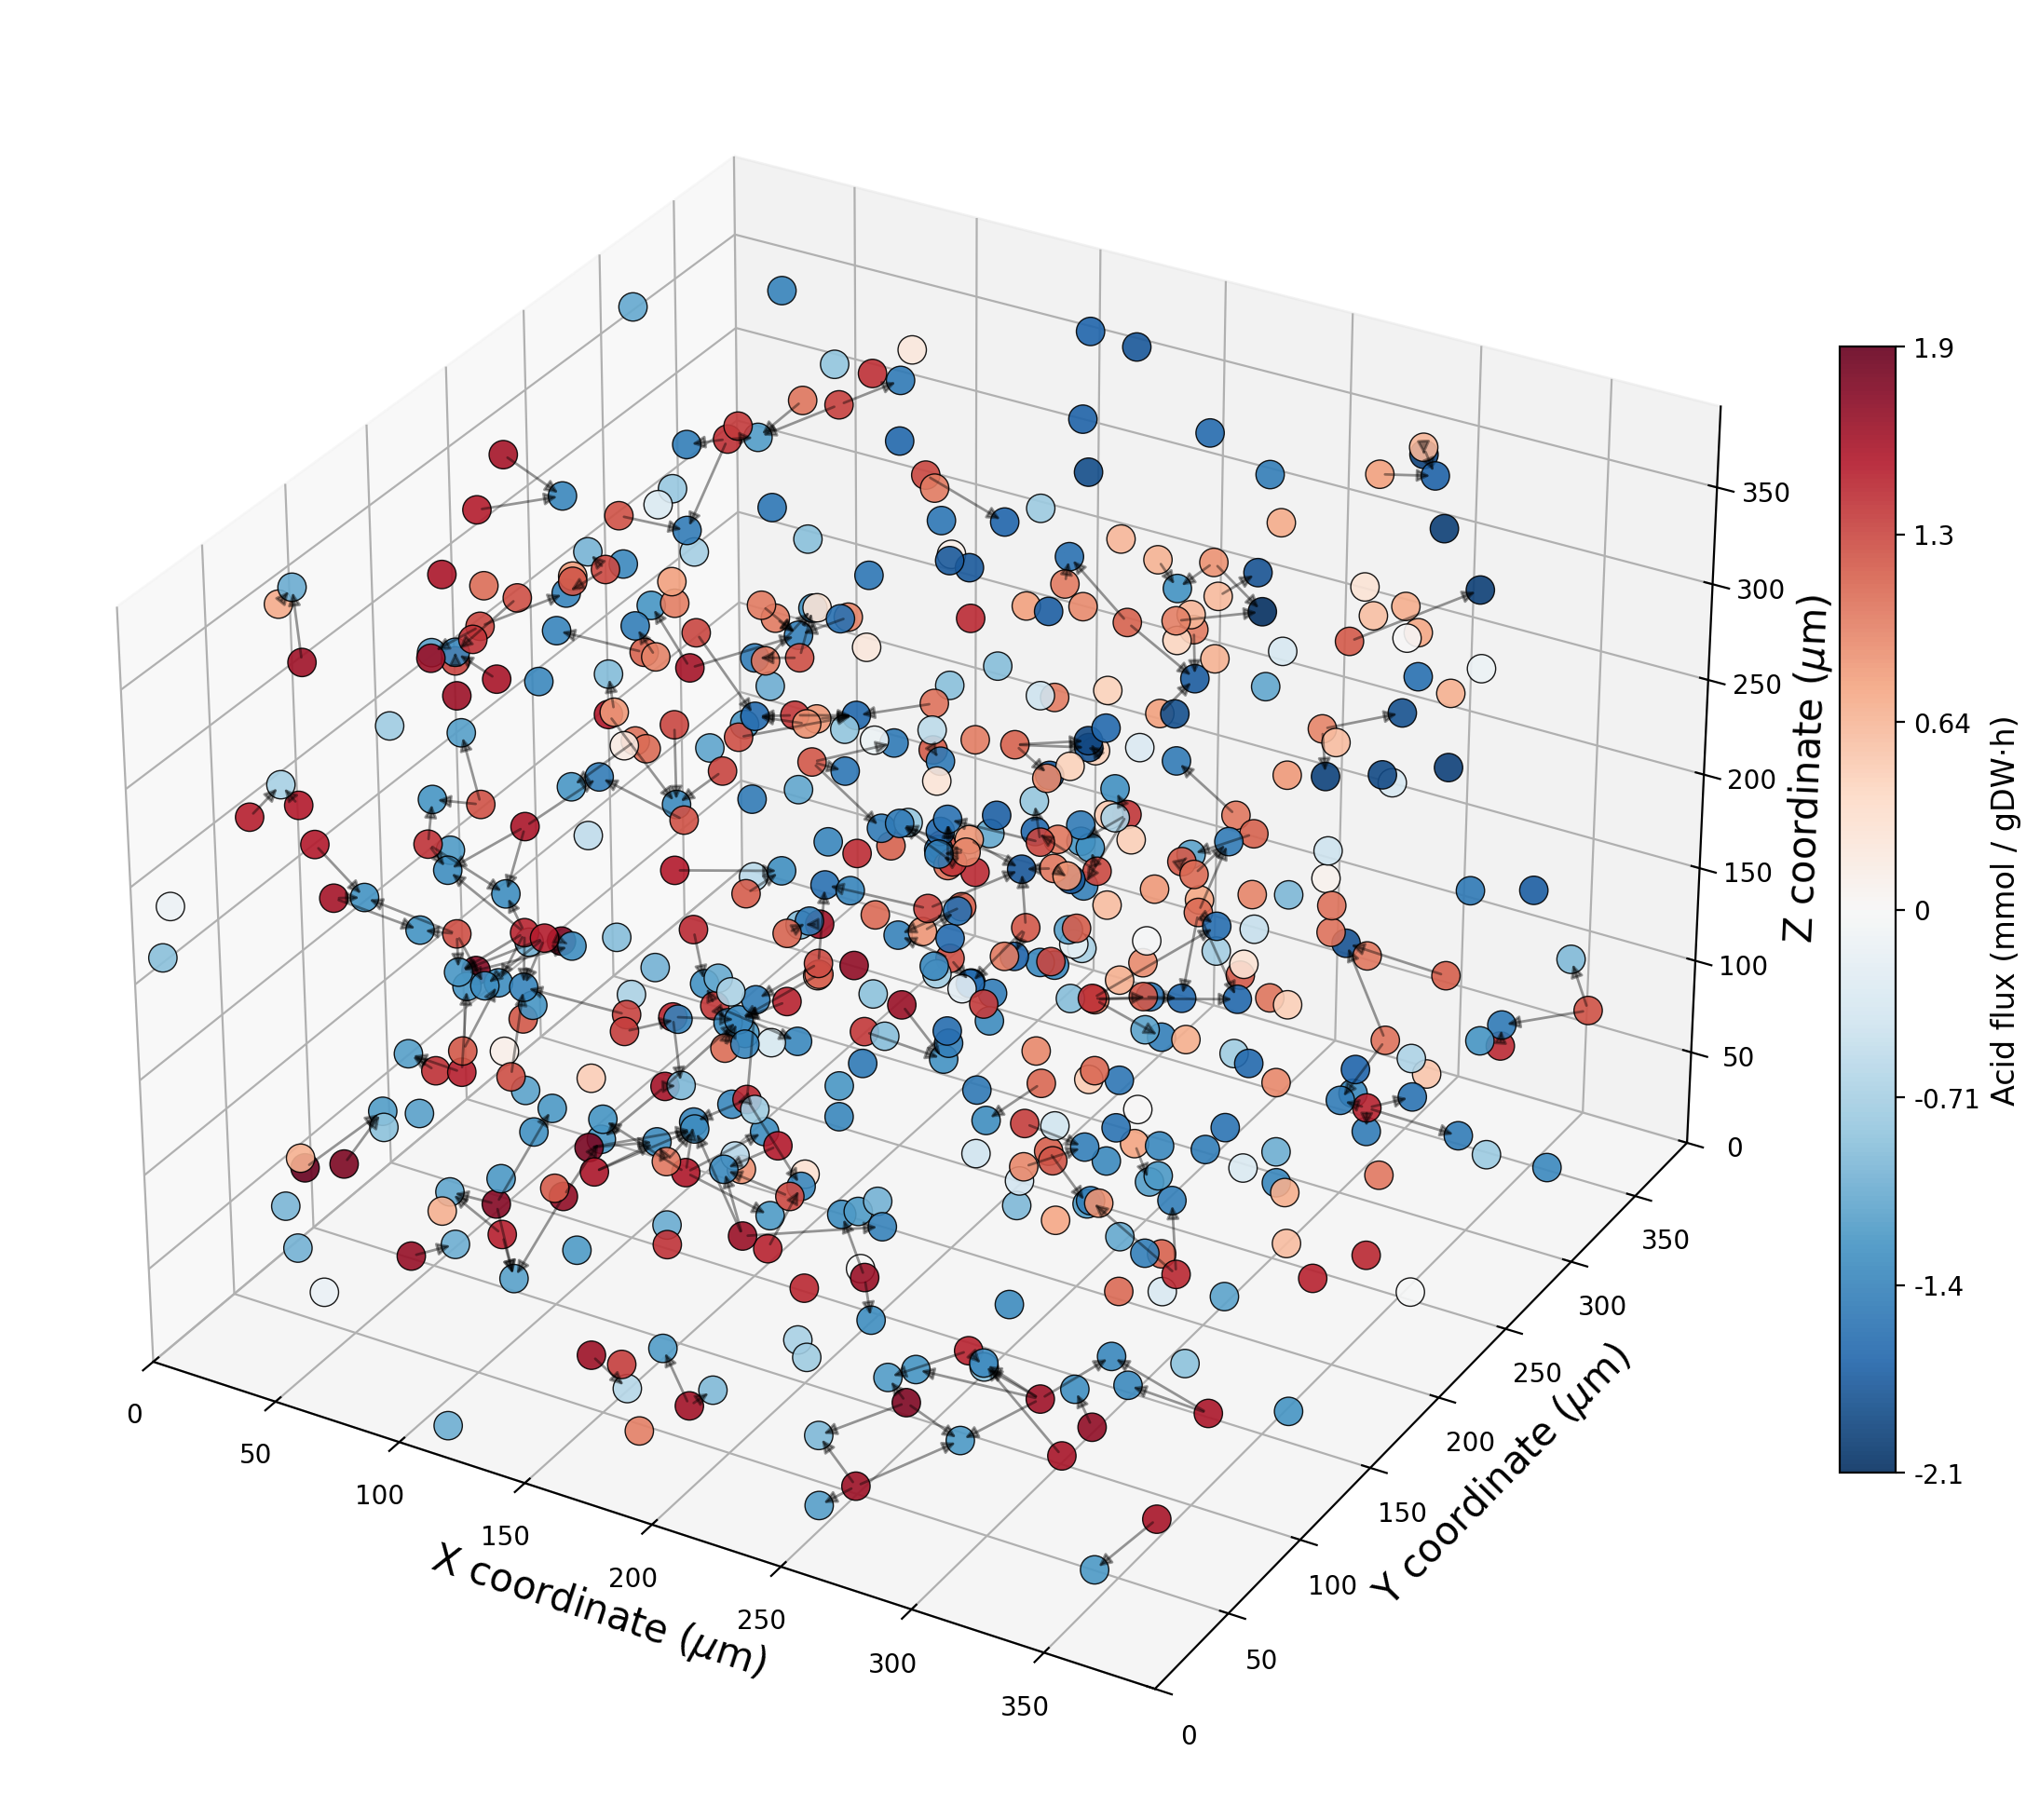

In [13]:
results = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep = '\t')
#results = results.iloc[0:405]
n_cells = 821
cell_dens_mg = 37.148  #mg/L
cell_mass = 0.5E-12 #g /cell
cell_dens = cell_dens_mg*1E-6/cell_mass   # cells/mL

V = n_cells/cell_dens *1E-6  #m³
L = V**(1/3) * 1E6
L = int(L)
L
cell_pos = np.loadtxt('exchange_model/cells_pos_3D.dat')
cell_pos

L = 1.05 * max([max(c) for c in cell_pos])
f_a = results['ac']
plt.rcParams['figure.figsize'] = [13,13]

G, node_colors, node_sizes= plot_fluxes(cell_pos, f_a, compound = 'ac', window_size=L)
#G, node_colors, node_sizes, C= plot_fluxes(cell_pos, f_a, compound = 'ac', window_size=2000)



In [25]:
print(np.mean([np.mean(i) for i in C]))    

6.819106956850909e-07


In [26]:
np.mean(f_a)

-0.000132720160422099

In [27]:
np.sum(f_a)

-0.09900923967488584

In [15]:
from netgraph import get_geometric_layout

    
def plot_network(G, node_colors, node_sizes):
    
    edge_length = {}
    for edge in G.edges(data='length'):
        edge_length[(edge[0], edge[1])] = edge[2]/1000
        
    #pos = nx.spring_layout(G, seed=20)
    pos = get_geometric_layout(list(G.edges), edge_length=edge_length,origin=(0,0), scale=(50,50), pad_by=0)
    nx.draw_networkx_nodes(G, pos, node_size=[i*2000 for i in list(node_sizes.values())], 
                  node_color = list(node_colors.values()),node_shape='o',
                    linewidths=0.5,edgecolors ='black')

    for edge in G.edges(data='weight'):
        nx.draw_networkx_edges(G, pos, edgelist=[edge], width=edge[2]*400,  
                                 arrowsize=20, edge_color='black')
    plt.rcParams['figure.figsize'] = [20,15]
        

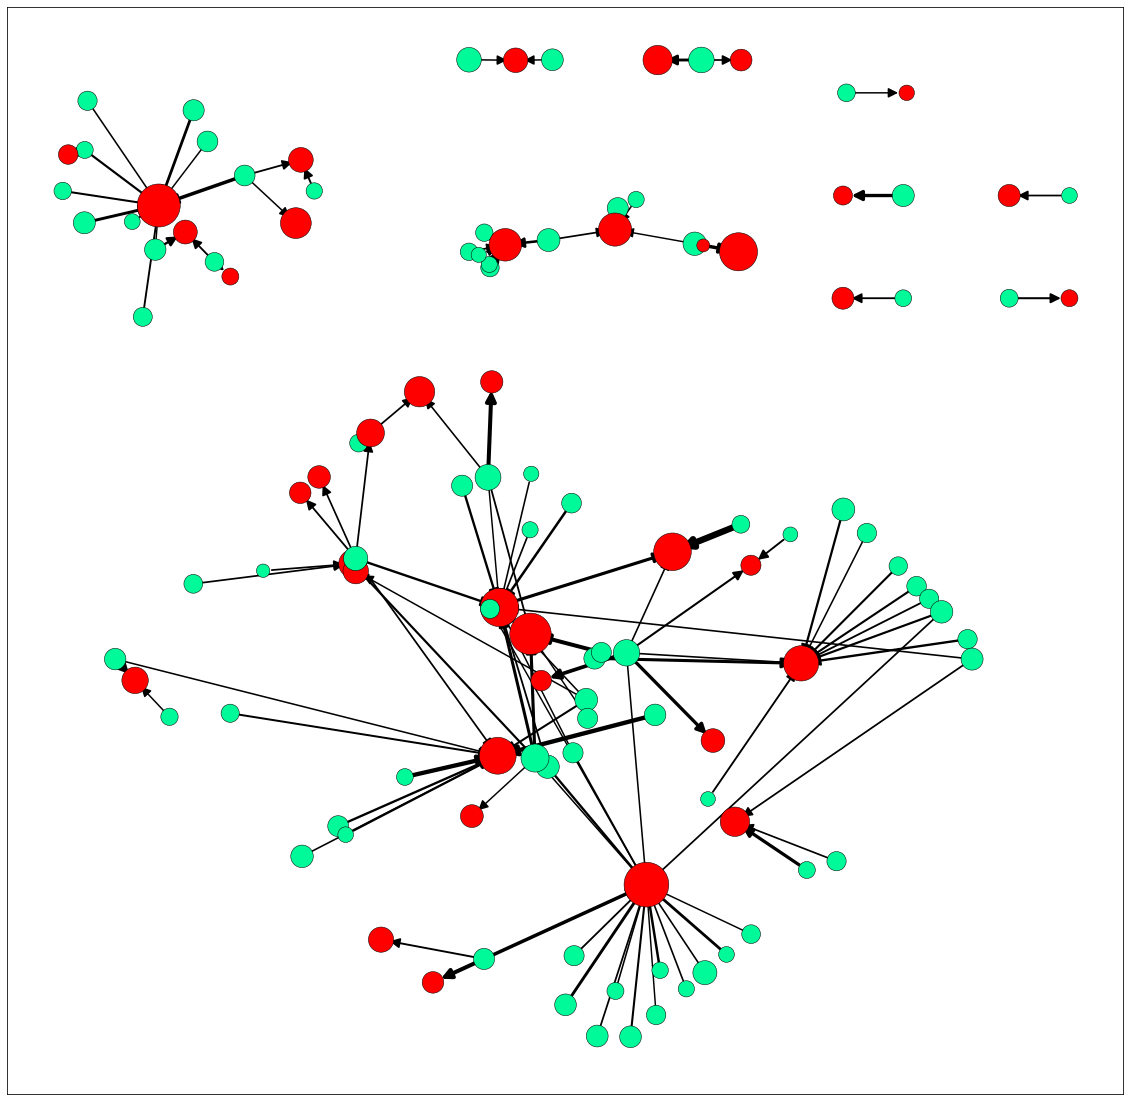

In [18]:
plt.rcParams['figure.figsize'] = [20,20]
plot_network(G, node_colors, node_sizes)

2.948717948717949 1.4375


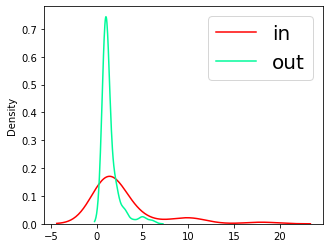

In [21]:
in_degree_dist = {}
in_degree = [i[1] for i in G.in_degree if i[1]!=0]
for i in range(1, max(in_degree)+1):
    in_degree_dist[i] = in_degree.count(i)


out_degree = [i[1] for i in G.out_degree if i[1]!=0]
out_degree_dist = {}
for i in range(1, max(out_degree)+1):
    out_degree_dist[i] = out_degree.count(i)
    
print(np.mean(in_degree), np.mean(out_degree))
plt.rcParams['figure.figsize'] = [5, 4]

sns.kdeplot(in_degree, c='red')
sns.kdeplot(out_degree, c='mediumspringgreen')
plt.legend(['in', 'out'], fontsize=20)

In [313]:
in_degree_dist

{1: 19, 2: 5, 3: 4, 4: 0, 5: 0, 6: 1, 7: 2, 8: 1, 9: 1, 10: 0, 11: 0, 12: 1}

In [317]:
out_degree_dist

{1: 53, 2: 9, 3: 3, 4: 0, 5: 2}

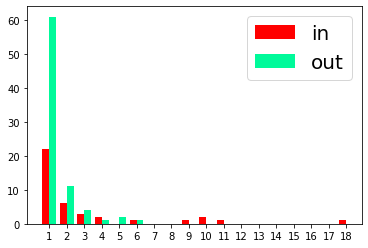

In [25]:
in_degree_dist = {}
in_degree = [i[1] for i in G.in_degree if i[1]!=0]
for i in range(1, max(in_degree)+1):
    in_degree_dist[i] = in_degree.count(i)


out_degree = [i[1] for i in G.out_degree if i[1]!=0]
out_degree_dist = {}
for i in range(1, max(out_degree)+1):
    out_degree_dist[i] = out_degree.count(i)
plt.rcParams['figure.figsize'] = [6, 4]

width = 0.4
x1 = np.arange(len(in_degree_dist)+1)[1:]
x2 = np.arange(len(out_degree_dist)+1)[1:]
plt.xticks(np.arange(min(x1), max(x1)+1, 1.0))

plt.bar(x1-0.2, in_degree_dist.values(), width, color='red') 
plt.bar(x2+0.2, out_degree_dist.values(), width, color='mediumspringgreen') 
plt.legend(['in', 'out'], fontsize=20)

In [285]:
nx.algorithms.connectivity.average_node_connectivity(G)


0.00891089108910891

0.0035799268990684523


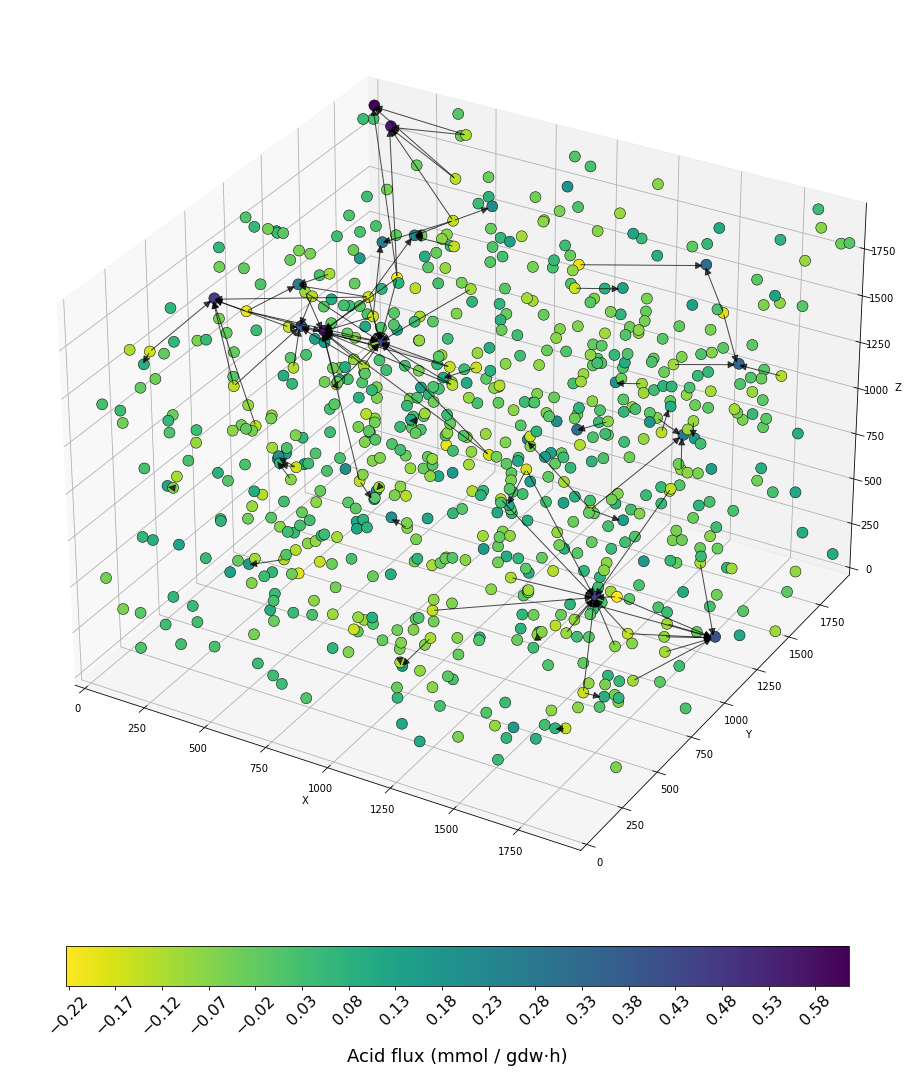

In [26]:
f_a = [i[3] for i in points_2]
cell_pos = np.loadtxt('configurations/cells_pos_3D_configuration_2.dat')
plt.rcParams['figure.figsize'] = [18,18]
G_2, node_colors_2, node_sizes_2 = plot_fluxes(cell_pos, f_a, compound = 'ac', window_size=2000)


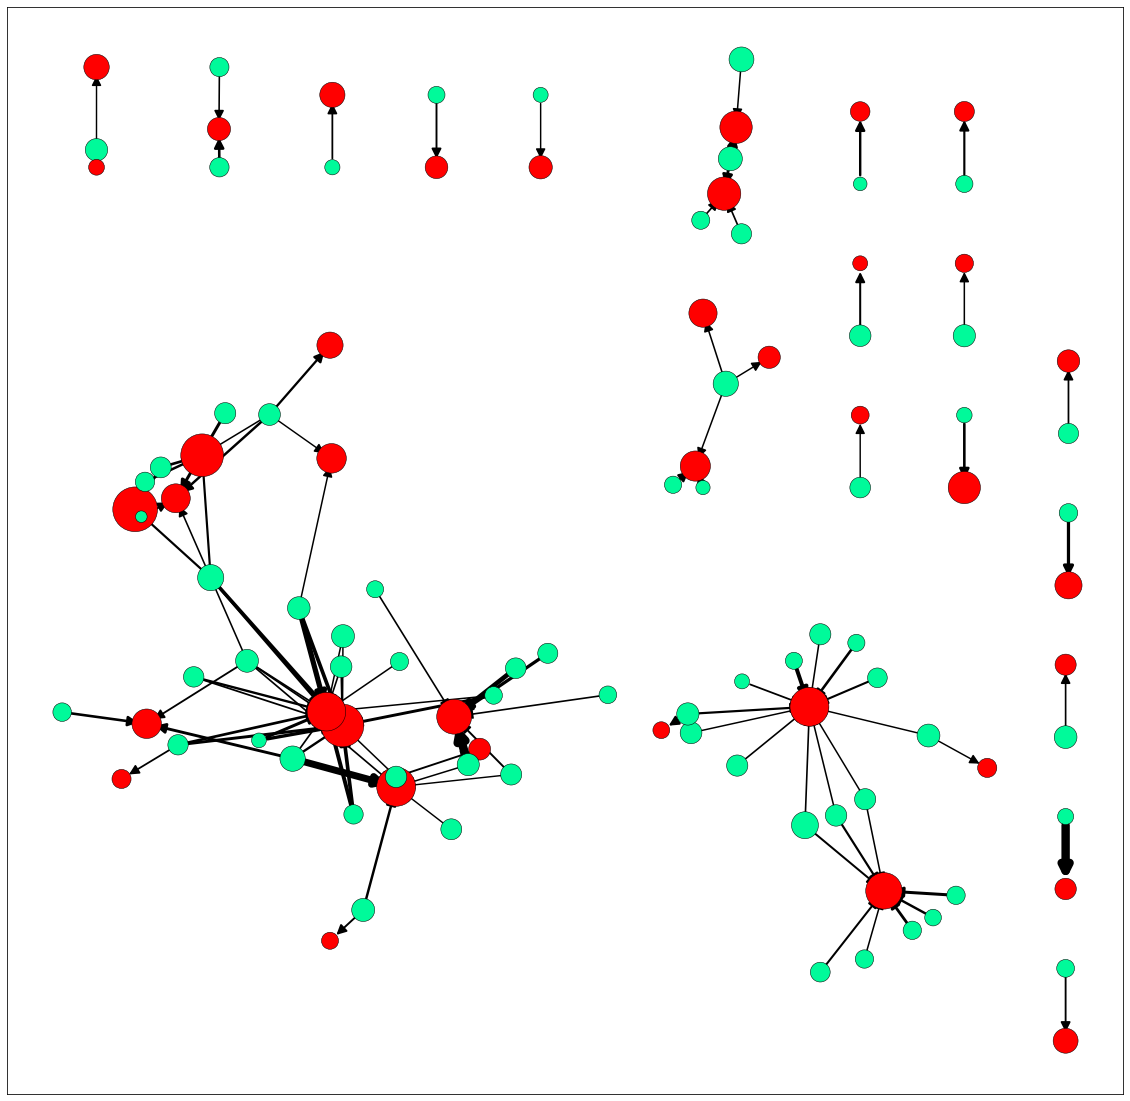

In [32]:
plt.rcParams['figure.figsize'] = [20,20]

plot_network(G_2, node_colors_2, node_sizes_2)

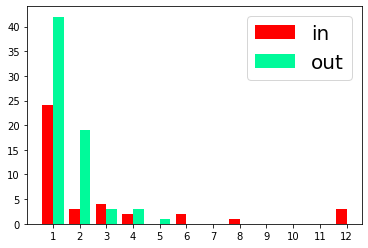

In [33]:
in_degree_dist = {}
in_degree = [i[1] for i in G_2.in_degree if i[1]!=0]
for i in range(1, max(in_degree)+1):
    in_degree_dist[i] = in_degree.count(i)


out_degree = [i[1] for i in G_2.out_degree if i[1]!=0]
out_degree_dist = {}
for i in range(1, max(out_degree)+1):
    out_degree_dist[i] = out_degree.count(i)
width = 0.4
x1 = np.arange(len(in_degree_dist)+1)[1:]
x2 = np.arange(len(out_degree_dist)+1)[1:]
plt.rcParams['figure.figsize'] = [6, 4]

plt.bar(x1-0.2, in_degree_dist.values(), width, color='red') 
plt.bar(x2+0.2, out_degree_dist.values(), width, color='mediumspringgreen') 
plt.xticks(np.arange(min(x1), max(x1)+1, 1.0))

plt.legend(['in', 'out'], fontsize=20)

0.003613724661362938


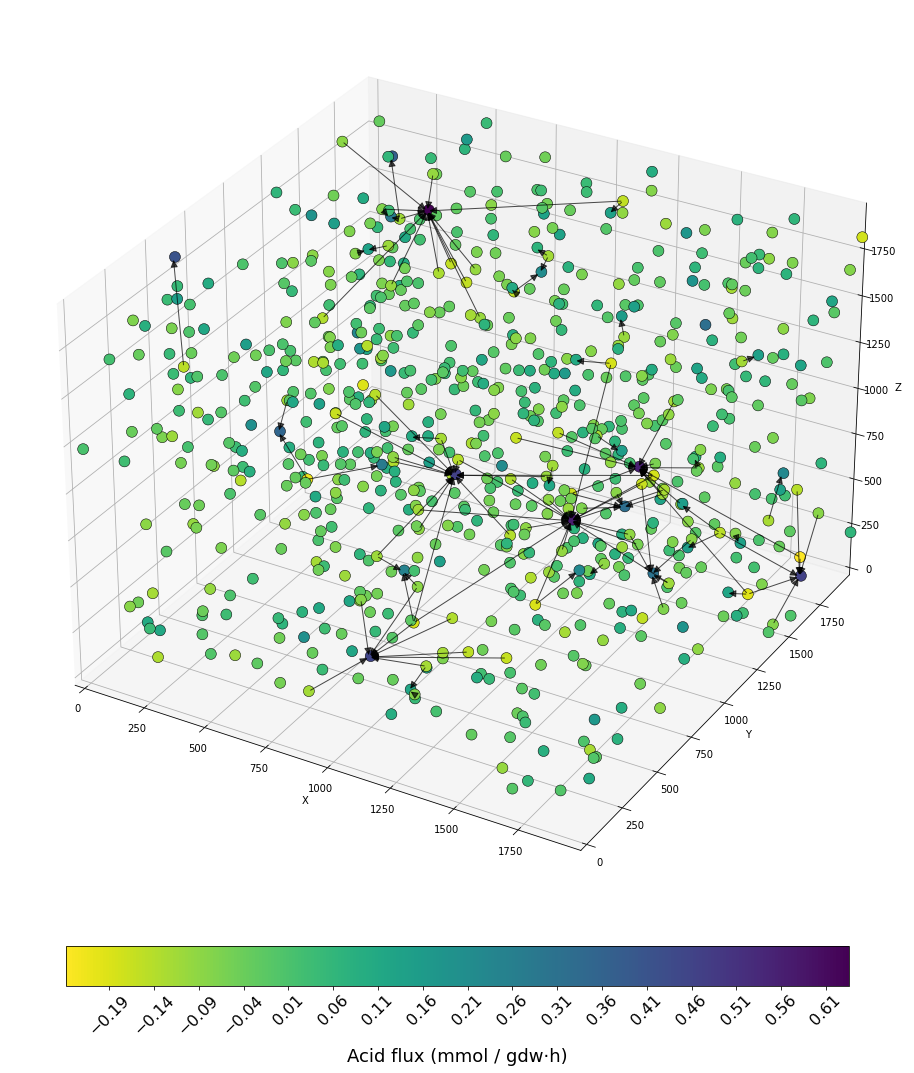

In [34]:
f_a = [i[3] for i in points_3]
cell_pos = np.loadtxt('configurations/cells_pos_3D_configuration_3.dat')
plt.rcParams['figure.figsize'] = [18,18]

G_3, node_colors_3, node_sizes_3 = plot_fluxes(cell_pos, f_a, compound = 'ac', window_size=2000)


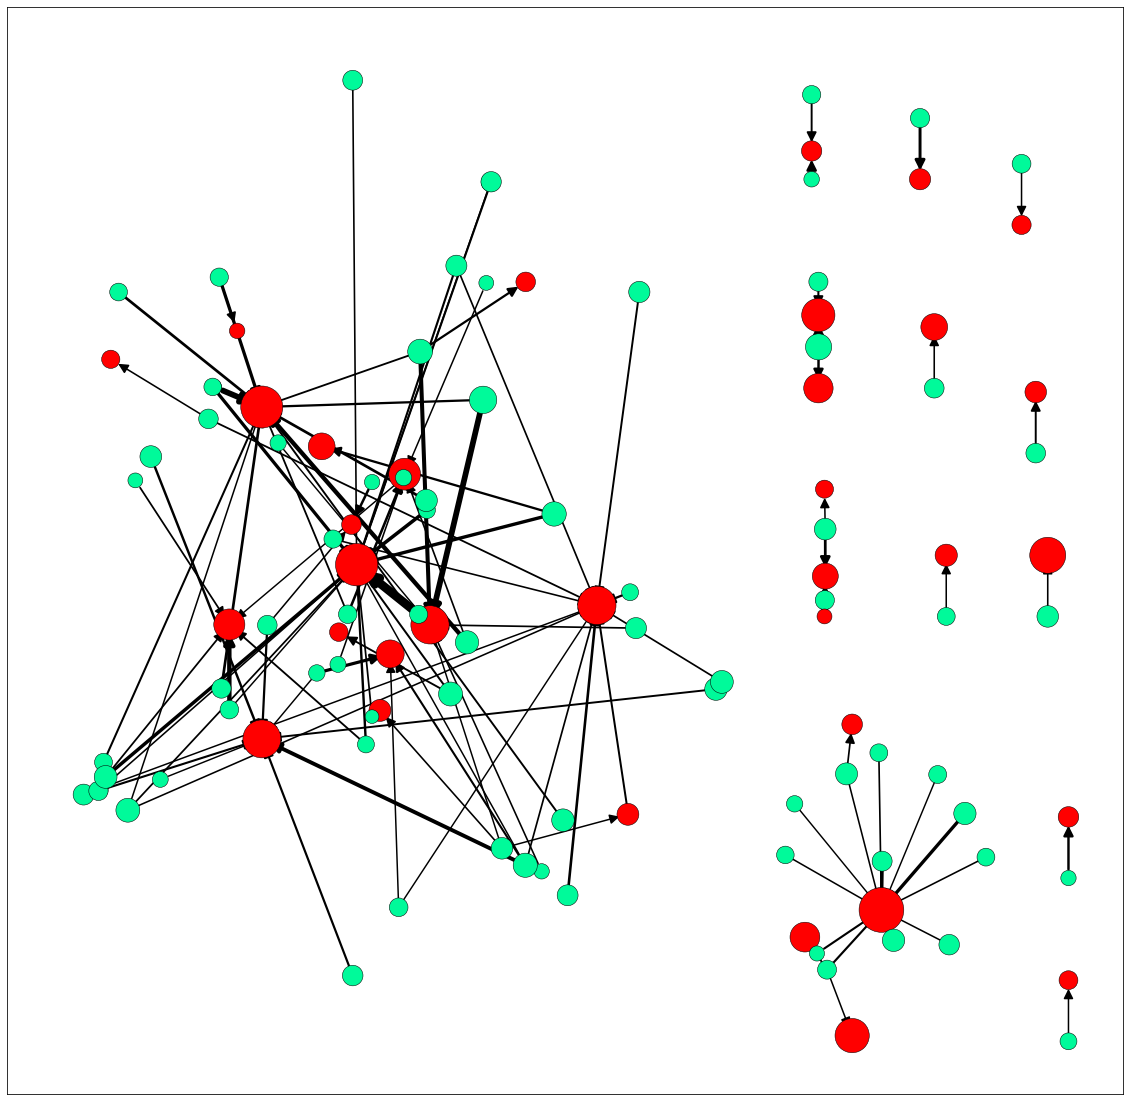

In [37]:
plt.rcParams['figure.figsize'] = [20,20]

plot_network(G_3, node_colors_3, node_sizes_3)

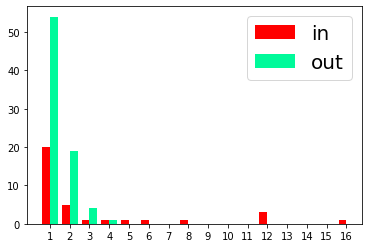

In [38]:
in_degree_dist = {}
in_degree = [i[1] for i in G_3.in_degree if i[1]!=0]
for i in range(1, max(in_degree)+1):
    in_degree_dist[i] = in_degree.count(i)


out_degree = [i[1] for i in G_3.out_degree if i[1]!=0]
out_degree_dist = {}
for i in range(1, max(out_degree)+1):
    out_degree_dist[i] = out_degree.count(i)

width= 0.4
x1 = np.arange(len(in_degree_dist)+1)[1:]
x2 = np.arange(len(out_degree_dist)+1)[1:]
plt.rcParams['figure.figsize'] = [6, 4]

plt.bar(x1-0.2, in_degree_dist.values(), width, color='red') 
plt.bar(x2+0.2, out_degree_dist.values(), width, color='mediumspringgreen') 
plt.xticks(np.arange(min(x1), max(x1)+1, 1.0))

plt.legend(['in', 'out'], fontsize=20)